# TED 03 - Experimento B: recuperação e ordenação por similaridade
**Projeto:** IAnjos de Patas · **Base:** PetFinder.my mini (base tratada na TED 02)

**Pergunta:** depois de aplicar os requisitos obrigatórios de uma busca, ordenar os candidatos por vizinhos mais próximos (k-NN) aumenta a aderência às preferências opcionais em relação à ordem original? E em relação a uma regra simples?

Este notebook chama o mesmo script do repositório (`src/ted03_recomendacao.py`), para que notebook, terminal e documento usem exatamente o mesmo procedimento.

## 1. Decisões metodológicas
- **Abordagem:** recuperação de informação baseada em conteúdo; k-NN com distância de cosseno. Não há variável-alvo.
- **Representação:** `OneHotEncoder` nos campos estruturados (peso 3) + `TfidfVectorizer` nas descrições em inglês (peso 1), normalizados.
- **Divisão:** `GroupShuffleSplit` 80/20 (semente 42), agrupando descrições idênticas para não haver o mesmo texto no ajuste e no catálogo de teste.
- **Excluídos:** `AdoptionSpeed` (resultado histórico) e indicadores auxiliares de qualidade.
- **Comparadores:** ordem original, regra explícita (mais preferências atendidas) e k-NN, todos com os mesmos filtros obrigatórios.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd

ROOT = Path.cwd().resolve()
for pasta in [ROOT, *ROOT.parents]:
    if (pasta / 'src' / 'ted03_recomendacao.py').exists():
        ROOT = pasta
        break
sys.path.insert(0, str(ROOT / 'src'))
import ted03_recomendacao as exp

print('Raiz do projeto:', ROOT.name)
print('Cenários definidos:', len(exp.CONSULTAS))
cenarios = pd.DataFrame([{'id': q['id'], 'pedido': q['pedido'],
                          'obrigatórios': len(q['obrigatorio']), 'preferências': len(q['preferencias'])}
                         for q in exp.CONSULTAS])
cenarios

Raiz do projeto: ia
Cenários definidos: 17


,id,pedido,obrigatórios,preferências
0,Q01,Quero uma gata pequena e vacinada; de preferência castrada e de pelo curto.,4,2
1,Q02,Procuro um cachorro filhote; se possível vacinado e de porte médio.,2,2
2,Q03,Uma cadela adulta castrada; prefiro pelagem curta e cor preta.,4,2
3,Q04,Gato macho saudável; de preferência jovem e já vacinado.,3,2
4,Q05,"Cachorro de porte grande, vacinado; se der, castrado e de pelo médio.",3,2
5,Q06,"Gatinho filhote de pelo longo; tanto faz o sexo, prefiro branco.",3,1
6,Q07,"Cão sem raça definida, vacinado e castrado; preferência por cor marrom e porte médio.",4,2
7,Q08,"Gata adulta; prefiro castrada, vacinada e de pelo curto.",3,3
8,Q09,"Cachorro pequeno; se possível macho, jovem e vacinado.",2,3
9,Q10,Gato vacinado e castrado; preferência por cor cinza.,3,1


## 2. Executar o experimento
A função `executar` faz a divisão, ajusta os vetorizadores, avalia os 17 cenários e grava os resultados em `reports/TED03_recomendacao/`.

In [2]:
resultados, por_consulta = exp.executar(ROOT / 'data/processed/petfinder_mini_tratado.csv',
                                        ROOT / 'reports/TED03_recomendacao')
print(json.dumps(resultados['divisao'], ensure_ascii=False, indent=2))
print(json.dumps(resultados['cenarios'], ensure_ascii=False, indent=2))

{
  "estrategia": "GroupShuffleSplit 80/20 por grupo de descrição normalizada",
  "ajuste": 9287,
  "catalogo_teste": 2250,
  "catalogo_sem_duplicatas_exibidas": 2233,
  "grupos_compartilhados": 0
}
{
  "definidos": 17,
  "com_candidatos": 16,
  "sem_candidatos": 1
}


## 3. Métricas agregadas
**Aderência:** fração média das preferências opcionais atendidas pelos cinco primeiros resultados. **Todas as preferências:** fração de resultados que atendem a todas ao mesmo tempo. **Obrigatórios:** fração de resultados que respeitam os filtros (deve ser 100%).

In [3]:
agg = pd.DataFrame(resultados['metricas']).T
agg.index = ['Ordem original', 'Regra explícita', 'k-NN']
(agg * 100).round(2)

,aderencia_media,todas_preferencias_media,obrigatorios_respeitados
Ordem original,41.04,20.00,100.0
Regra explícita,96.25,96.25,100.0
k-NN,96.25,96.25,100.0


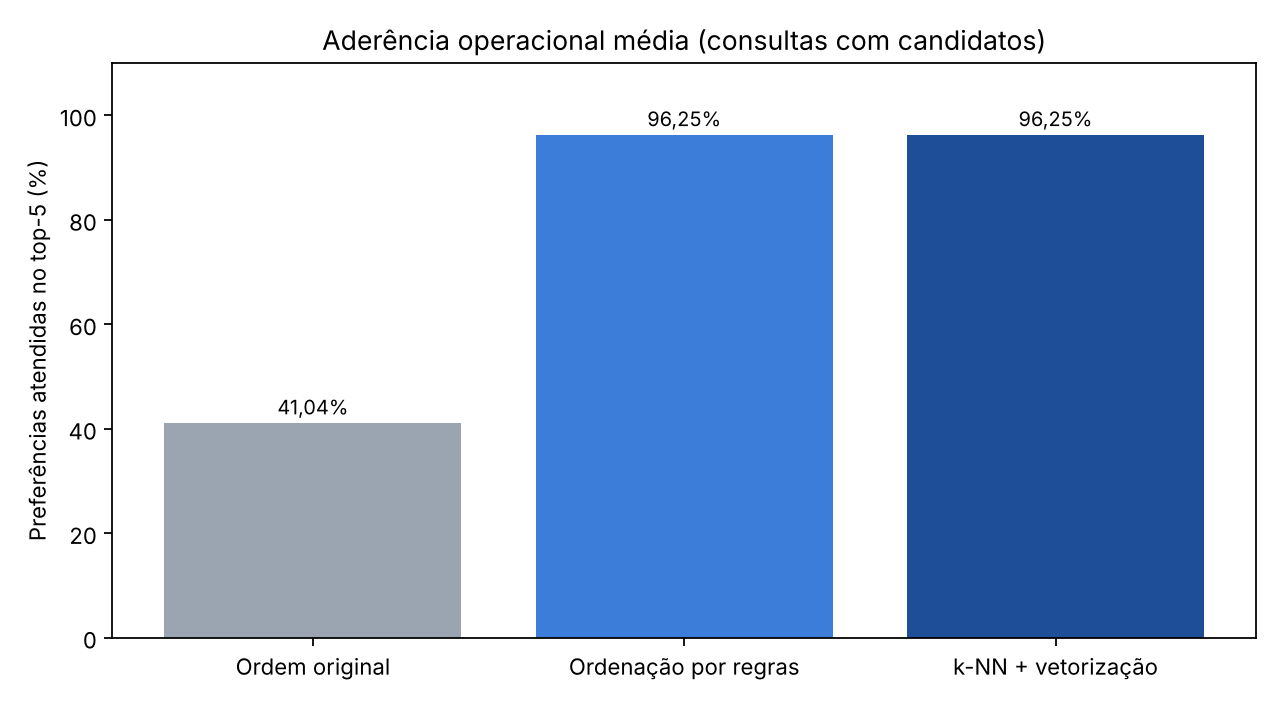

In [4]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'reports/TED03_recomendacao/figures/01_aderencia_media.png')))

## 4. Resultado por cenário

In [5]:
por_consulta[['id','candidatos','aderencia_ordem_original','aderencia_regra','aderencia_knn','todas_knn']].round(3)

,id,candidatos,aderencia_ordem_original,aderencia_regra,aderencia_knn,todas_knn
0,Q01,48,0.800,1.0,1.0,1.0
1,Q02,711,0.600,1.0,1.0,1.0
2,Q03,63,0.200,1.0,1.0,1.0
3,Q04,437,0.200,1.0,1.0,1.0
4,Q05,71,0.200,1.0,1.0,1.0
5,Q06,33,0.200,0.4,0.4,0.4
6,Q07,146,0.700,1.0,1.0,1.0
7,Q08,27,0.600,1.0,1.0,1.0
8,Q09,221,0.600,1.0,1.0,1.0
9,Q10,160,0.200,1.0,1.0,1.0


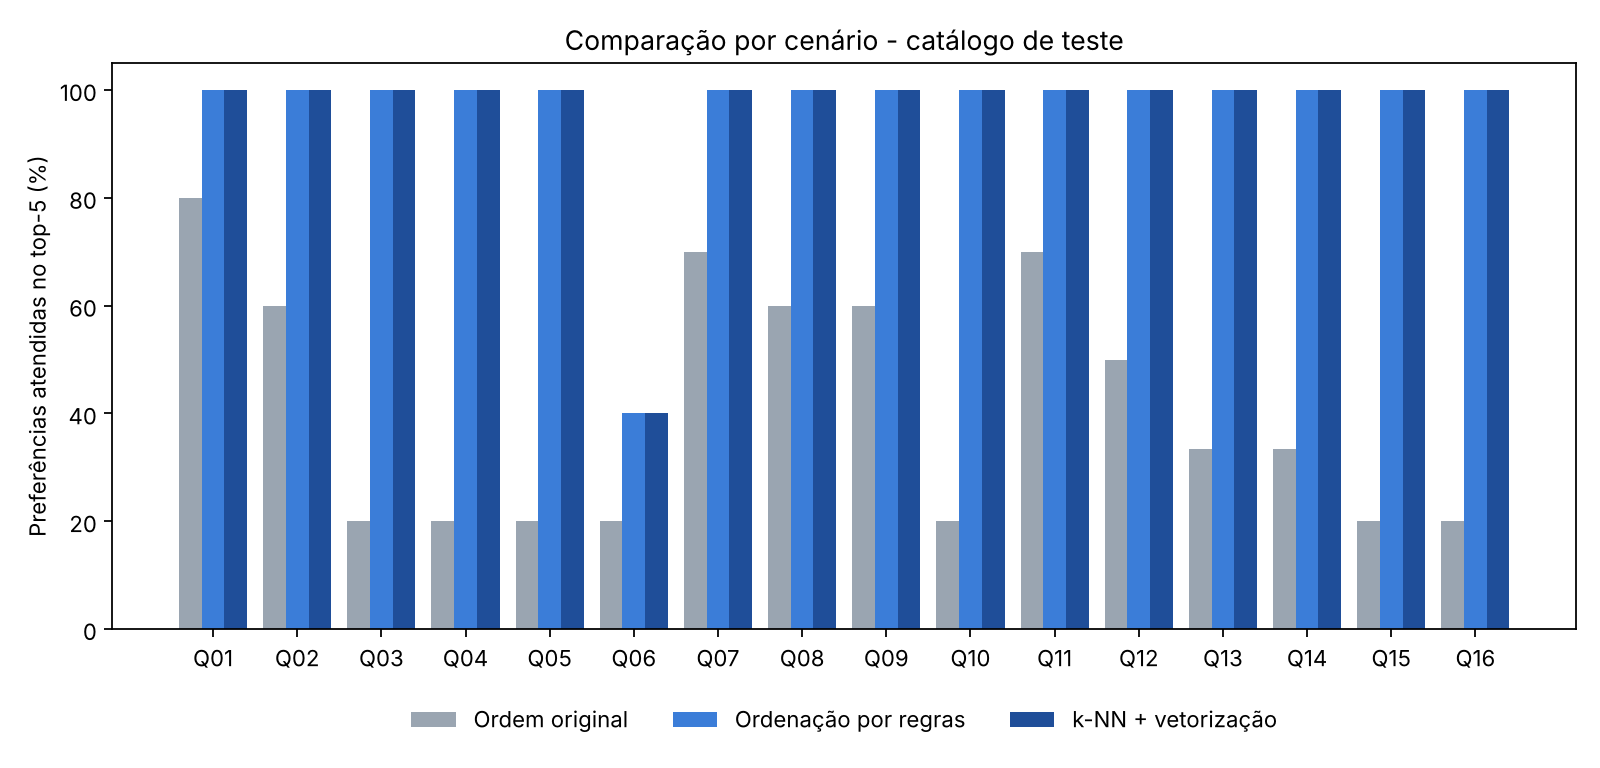

In [6]:
display(Image(filename=str(ROOT / 'reports/TED03_recomendacao/figures/02_comparacao_por_cenario.png')))

## 5. Demonstração: Q01 (com candidatos) e Q17 (sem candidatos)

In [7]:
_, _, _, catalogo, rec = exp.preparar(ROOT / 'data/processed/petfinder_mini_tratado.csv')
for qid in ['Q01', 'Q17']:
    q = next(c for c in exp.CONSULTAS if c['id'] == qid)
    cand = exp.filtrar(catalogo, q['obrigatorio'])
    print(f"{qid}: {q['pedido']}  ->  {len(cand)} candidatos elegíveis")
    if len(cand):
        top = rec.knn(cand, q)
        top['pref_atendidas'] = exp.atendidas(top, q['preferencias'])
        print(top[['linha_origem', *q['preferencias'], 'AgeBand', 'pref_atendidas', 'similaridade']].round(3).to_string(index=False))
    else:
        print('Nenhum perfil atende aos requisitos; nenhum animal é sugerido.')
    print()

Q01: Quero uma gata pequena e vacinada; de preferência castrada e de pelo curto.  ->  48 candidatos elegíveis
 linha_origem Sterilized FurLength           AgeBand  pref_atendidas  similaridade
        10394        Yes     Short        7-24 meses               2         0.735
           16        Yes     Short         0-6 meses               2         0.735
         1744        Yes     Short acima de 24 meses               2         0.735
          951        Yes     Short        7-24 meses               2         0.735
         3666        Yes     Short        7-24 meses               2         0.735

Q17: Gata filhote, grande, de pelo longo, castrada e com ferimento grave.  ->  0 candidatos elegíveis
Nenhum perfil atende aos requisitos; nenhum animal é sugerido.



## 6. Interpretação
- Os filtros obrigatórios foram respeitados em 100% dos resultados nos três métodos, porque são aplicados antes da ordenação.
- O k-NN e a regra explícita **empataram em todos os cenários com candidatos**: como a consulta só contém campos estruturados, a similaridade de cosseno passa a contar, na prática, quantos campos coincidem. Para atributos confirmados, a regra é mais simples e auditável.
- Q06 mostra um limite dos dados: só dois filhotes de pelo longo e cor branca existem no catálogo de teste, então nenhum método alcança 100%.
- Q17 não tem candidatos: a resposta é vazia, sem relaxar filtros nem inventar animais.
- As métricas usam os mesmos campos que filtram e ordenam; não medem relevância percebida, compatibilidade nem sucesso de adoção.